In [2]:

import pandas as pd

# Load the Superstore dataset
df = pd.read_csv('/superstore_sales.csv')

# Display first 5 rows
df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [3]:

# Check number of rows and columns
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())


Dataset Shape: (10800, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   obj

In [4]:

# Create a copy of the original dataset
clean_df = df.copy()

# Remove rows missing important information
clean_df = clean_df.dropna(
    subset=['Order Date', 'Sales', 'Profit',
            'Category', 'Region', 'Segment']
)

# Remove exact duplicate rows
clean_df = clean_df.drop_duplicates()

# Convert dates into proper date format
clean_df['Order Date'] = pd.to_datetime(
    clean_df['Order Date'],
    errors='coerce'
)

# Remove rows with invalid dates
clean_df = clean_df.dropna(subset=['Order Date'])

# Extract year and month
clean_df['Year'] = clean_df['Order Date'].dt.year
clean_df['Month'] = clean_df['Order Date'].dt.month
clean_df['Year-Month'] = clean_df['Order Date'].dt.to_period('M')

# Check cleaned dataset
print("Original Dataset:", df.shape)
print("Cleaned Dataset:", clean_df.shape)
print("Remaining Missing Values:")
print(clean_df.isnull().sum())


Original Dataset: (10800, 21)
Cleaned Dataset: (9994, 24)
Remaining Missing Values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
Year              0
Month             0
Year-Month        0
dtype: int64


In [5]:

# Calculate business KPIs

total_sales = clean_df['Sales'].sum()
total_profit = clean_df['Profit'].sum()
total_orders = clean_df['Order ID'].nunique()
profit_margin = (total_profit / total_sales) * 100

print("SUPERSTORE SALES ANALYSIS")
print("-------------------------")
print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Profit Margin:", round(profit_margin, 2), "%")


SUPERSTORE SALES ANALYSIS
-------------------------
Total Sales: 2297200.86
Total Profit: 286397.02
Total Orders: 5009
Profit Margin: 12.47 %


Category-wise Sales and Profit:
                       Sales       Profit
Category                                 
Furniture        741999.7953   18451.2728
Office Supplies  719047.0320  122490.8008
Technology       836154.0330  145454.9481


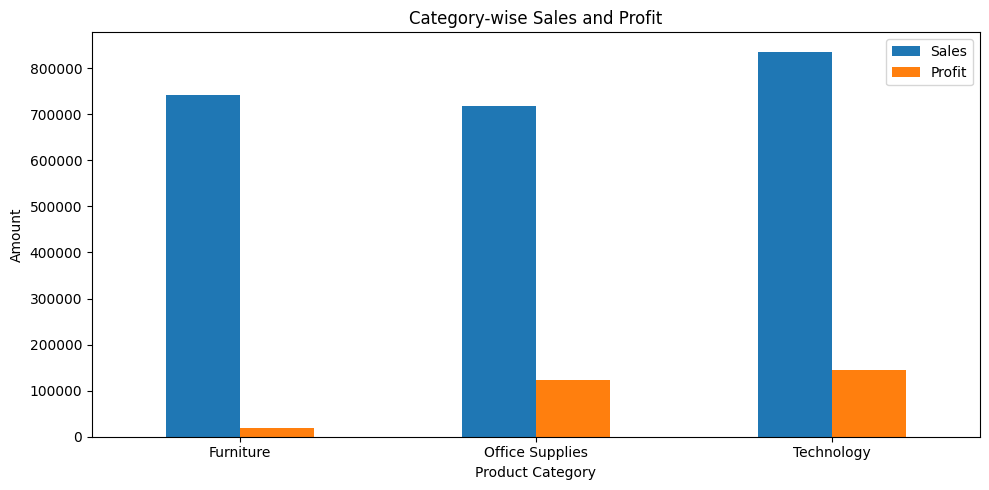

In [6]:

import matplotlib.pyplot as plt

# Calculate category-wise sales and profit
category_analysis = clean_df.groupby('Category')[
    ['Sales', 'Profit']
].sum()

print("Category-wise Sales and Profit:")
print(category_analysis)

# Create bar chart
category_analysis.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Category-wise Sales and Profit')
plt.xlabel('Product Category')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()


Region-wise Sales and Profit:
               Sales       Profit
Region                           
Central  501239.8908   39706.3625
East     678781.2400   91522.7800
South    391721.9050   46749.4303
West     725457.8245  108418.4489


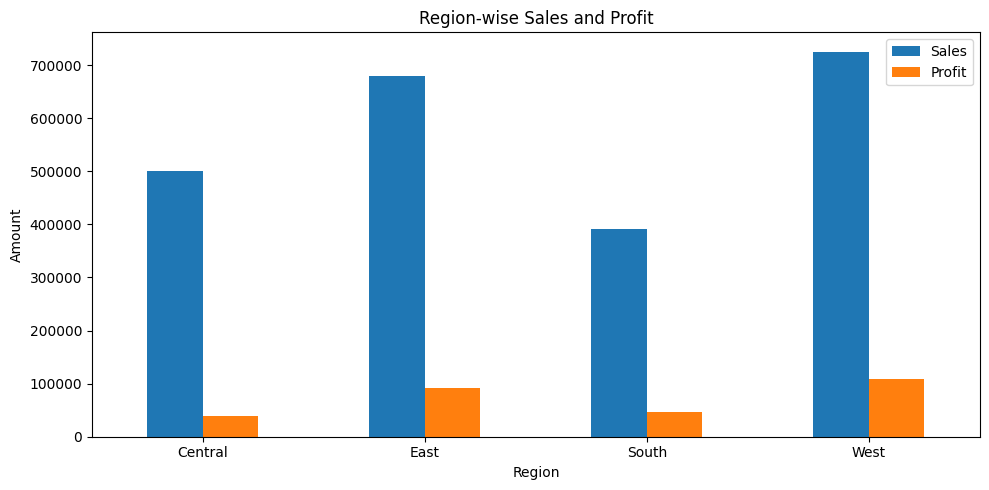

In [7]:

# Calculate region-wise sales and profit
region_analysis = clean_df.groupby('Region')[
    ['Sales', 'Profit']
].sum()

print("Region-wise Sales and Profit:")
print(region_analysis)

# Create bar chart
region_analysis.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Region-wise Sales and Profit')
plt.xlabel('Region')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


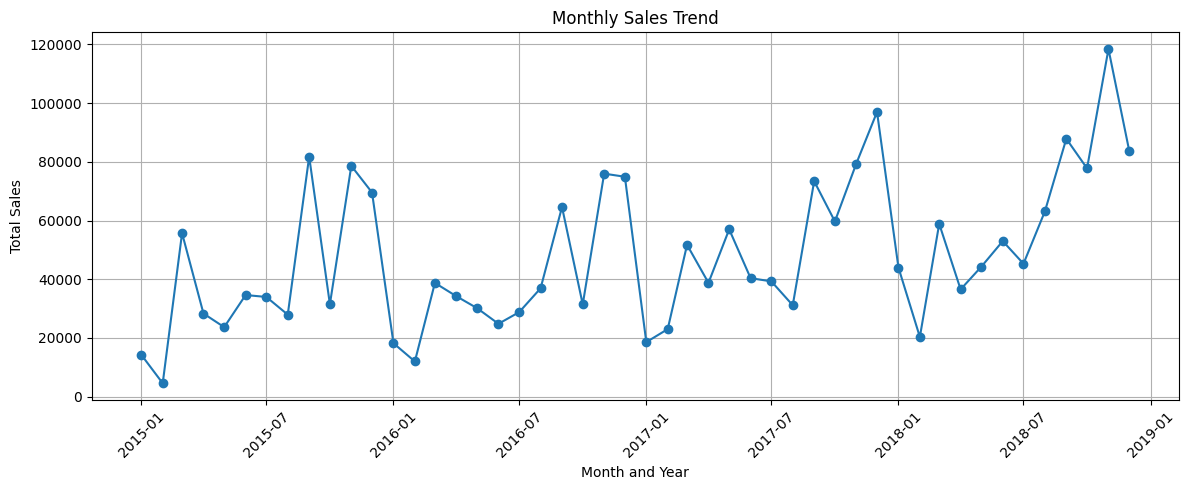

Highest Sales Month: 2018-11-01 00:00:00
Highest Monthly Sales: 118447.82
Lowest Sales Month: 2015-02-01 00:00:00
Lowest Monthly Sales: 4519.89


In [8]:

# Calculate monthly sales
monthly_sales = clean_df.groupby('Year-Month')['Sales'].sum()

# Convert months to timestamps for plotting
monthly_sales.index = monthly_sales.index.to_timestamp()

# Create line chart
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker='o'
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month and Year')
plt.ylabel('Total Sales')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Display highest and lowest sales months
print("Highest Sales Month:", monthly_sales.idxmax())
print("Highest Monthly Sales:", round(monthly_sales.max(), 2))

print("Lowest Sales Month:", monthly_sales.idxmin())
print("Lowest Monthly Sales:", round(monthly_sales.min(), 2))


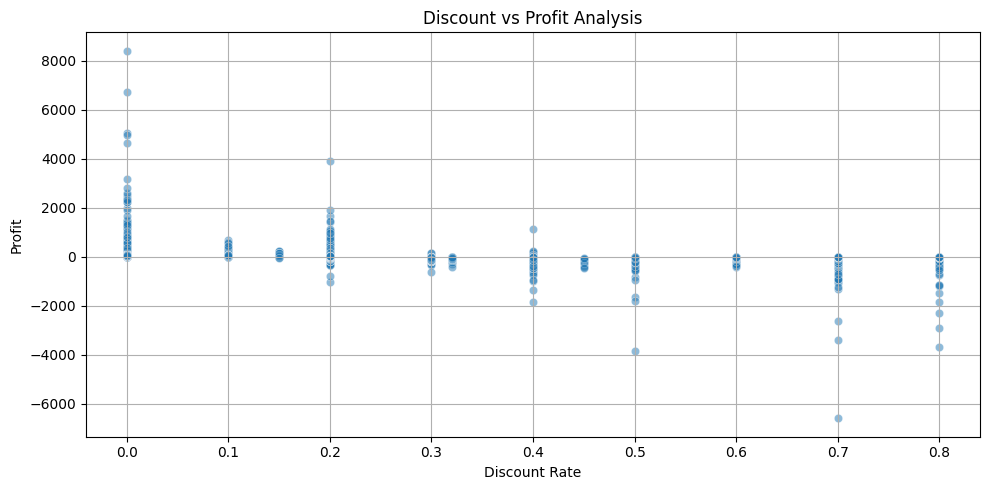

Discount-Profit Correlation: -0.219


In [9]:

import seaborn as sns
import matplotlib.pyplot as plt

# Create discount vs profit scatter plot
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=clean_df,
    x='Discount',
    y='Profit',
    alpha=0.5
)

plt.title('Discount vs Profit Analysis')
plt.xlabel('Discount Rate')
plt.ylabel('Profit')
plt.grid(True)
plt.tight_layout()
plt.show()

# Calculate correlation
correlation = clean_df['Discount'].corr(
    clean_df['Profit']
)

print("Discount-Profit Correlation:",
      round(correlation, 3))


Customer Segment Analysis:
                    Sales       Profit
Segment                               
Consumer     1.161401e+06  134119.2092
Corporate    7.061464e+05   91979.1340
Home Office  4.296531e+05   60298.6785


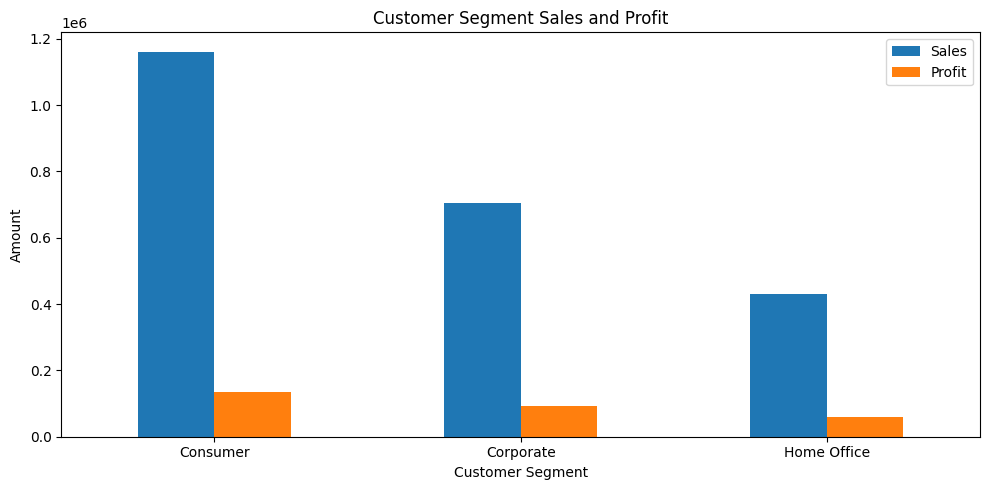

In [10]:

# Calculate customer segment performance
segment_analysis = clean_df.groupby('Segment')[
    ['Sales', 'Profit']
].sum()

print("Customer Segment Analysis:")
print(segment_analysis)

# Create bar chart
segment_analysis.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Customer Segment Sales and Profit')
plt.xlabel('Customer Segment')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Executive Summary and Key Business Findings

**Project:** Exploratory Data Analysis on Superstore Retail Sales

**Objective:** Analyze retail sales data to identify sales trends, profitability, customer behavior, and discount patterns.

### Key Business Findings

**1. Product Category Performance**

Technology generated the highest sales (836,154.03) and profit (145,454.95). Furniture generated substantial sales (741,999.80) but relatively low profit (18,451.27).

**Recommendation:** Investigate Furniture's low profitability and identify opportunities to improve margins.

**2. Regional Performance**

The West region achieved the highest sales (725,457.82) and profit (108,418.45). The Central region recorded the lowest total profit (39,706.36).

**Recommendation:** Investigate the factors contributing to lower profitability in the Central region.

**3. Monthly Sales Trends**

November 2018 recorded the highest monthly sales (118,447.82), while February 2015 recorded the lowest (4,519.89).

**Recommendation:** Examine seasonal patterns across multiple years to improve inventory and sales planning.

**4. Discount Impact on Profit**

The correlation between discount and profit was -0.219, indicating a weak negative linear relationship. Several transactions with high discounts experienced substantial losses.

**Recommendation:** Review discount policies, especially for heavily discounted products, and investigate their impact on profitability.

**5. Customer Segment Performance**

The Consumer segment generated the highest sales (approximately 1.16 million) and profit (134,119.21). Home Office recorded the lowest total sales and profit.

**Recommendation:** Maintain strong Consumer engagement while exploring profitable growth opportunities in other segments.

### Conclusion

The analysis identifies Technology, the West region, and the Consumer segment as major contributors to sales and profit. Furniture profitability and high-discount transactions deserve further investigation.

These findings can support better pricing, marketing, inventory planning, and business decision-making.
